# Analyse der Durchlaufzeiten im Wareneingang (MainLogistik GmbH)

Das Notebook wird von oben nach unten ausgeführt. Die Rohdatei wird nur gelesen und nie verändert.

| Schritt | Inhalt | Ergebnisdateien (Ordner 03_Ergebnisse) |
| --- | --- | --- |
| 1 | Daten einlesen und prüfen | – |
| 2 | Fehler suchen und Daten bereinigen | datenfehler_liste.csv, wareneingang_bereinigt.csv |
| 3 | Kennzahlen berechnen | kennzahlen_gesamt.csv, kennzahlen_schritte.csv, median_je_gruppe.csv |
| 4 | Statistik: Korrelation, Gruppentest, Regression | spearman.csv, kruskal_wallis.csv, vif.csv, regression_koeffizienten.csv |
| 5 | Diagramme | abb3_verteilung_schritte.png, abb4_warenart_paletten.png |
| 6 | Verbesserungsvorschläge und Wirtschaftlichkeit | verbesserungen.csv |
| 7 | Tests (Qualitätssicherung) | – |

In [1]:
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

## 1. Daten einlesen und prüfen

In [2]:
ERG = "../03_Ergebnisse/"   # Ordner für die Ergebnisse
ZEIT = ["ts_ankunft", "ts_annahme", "ts_kontrolle", "ts_erfassung", "ts_einlagerung_bereit"]

# Fingerabdruck der Rohdatei (am Ende prüfen wir, ob sie unverändert ist)
hash_vorher = hashlib.md5(open("../01_Rohdaten/wareneingang_roh.csv", "rb").read()).hexdigest()

df = pd.read_csv("../01_Rohdaten/wareneingang_roh.csv", sep=";", encoding="utf-8-sig", parse_dates=ZEIT)
anzahl_roh = len(df)

print("Zeilen:", df.shape[0], "| Spalten:", df.shape[1])
print("\nVerschiedene Lieferungen:", df["lieferung_id"].nunique())
print()
print(df.isna().sum())
print()
display(df.describe())
df.head()

Zeilen: 2109 | Spalten: 11

Verschiedene Lieferungen: 2099

lieferung_id              0
lieferant_id              0
warenart                  0
anzahl_paletten           0
anzahl_positionen         0
avisiert                  0
ts_ankunft                0
ts_annahme                4
ts_kontrolle             19
ts_erfassung              9
ts_einlagerung_bereit    10
dtype: int64



,anzahl_paletten,anzahl_positionen,ts_ankunft,ts_annahme,ts_kontrolle,ts_erfassung,ts_einlagerung_bereit
count,2109.000000,2109.000000,2109,2105,2090,2100,2099
mean,6.404931,6.542437,2027-02-15 23:58:00.771455,2027-02-15 23:53:08.820902,2027-02-16 00:40:19.534928,2027-02-16 01:18:14.324761,2027-02-15 23:43:36.593616
min,0.000000,1.000000,2027-01-04 06:28:49,2027-01-04 07:02:19,2027-01-04 07:27:43,2027-01-04 07:51:27,2027-01-04 08:08:59
25%,4.000000,4.000000,2027-01-26 08:21:52,2027-01-26 08:47:32,2027-01-26 10:03:04.500000,2027-01-26 10:01:02.500000,2027-01-26 09:30:35
50%,6.000000,6.000000,2027-02-16 13:04:55,2027-02-16 12:27:49,2027-02-16 13:42:41,2027-02-16 13:17:10,2027-02-16 12:55:35
75%,8.000000,9.000000,2027-03-09 09:55:11,2027-03-09 10:06:45,2027-03-09 10:40:22.500000,2027-03-09 10:56:45,2027-03-09 09:55:33.500000
max,99.000000,24.000000,2027-03-31 15:32:31,2027-03-31 15:52:24,2027-03-31 16:04:43,2027-03-31 16:14:08,2027-03-31 16:31:21
std,5.042617,3.642039,NaN,NaN,NaN,NaN,NaN


,lieferung_id,lieferant_id,warenart,anzahl_paletten,anzahl_positionen,avisiert,ts_ankunft,ts_annahme,ts_kontrolle,ts_erfassung,ts_einlagerung_bereit
0,L-2027-00001,LF02,Kühlware,12,19,ja,2027-01-04 06:28:49,2027-01-04 07:02:19,2027-01-04 07:27:43,2027-01-04 07:51:27,2027-01-04 08:08:59
1,L-2027-00002,LF08,Kühlware,5,11,ja,2027-01-04 07:08:33,2027-01-04 07:24:45,2027-01-04 07:43:30,2027-01-04 08:05:06,2027-01-04 08:18:46
2,L-2027-00003,LF07,Trockenware,7,5,ja,2027-01-04 07:38:20,2027-01-04 08:03:02,2027-01-04 08:24:05,2027-01-04 08:32:02,2027-01-04 08:51:58
3,L-2027-00004,LF02,Kühlware,7,4,ja,2027-01-04 07:42:03,2027-01-04 08:10:32,2027-01-04 08:29:51,2027-01-04 08:46:17,2027-01-04 09:02:39
4,L-2027-00005,LF06,Kühlware,9,6,ja,2027-01-04 07:42:33,2027-01-04 08:13:44,2027-01-04 08:28:10,2027-01-04 08:39:44,2027-01-04 08:59:39


## 2. Fehler suchen und Daten bereinigen

In [3]:
# Fehler suchen. Jede Zeile bekommt höchstens einen Fehlergrund.
# Passen mehrere Regeln, gilt die erste (so arbeitet np.select).
regeln = [
    df.duplicated(),  # 1 Doppelte Zeile
    df[ZEIT].isna().any(axis=1),  # 2 Fehlender Zeitstempel
    (df["ts_kontrolle"] < df["ts_annahme"])  # 3 Falsche Reihenfolge
        | (df["ts_erfassung"] < df["ts_kontrolle"])
        | (df["ts_einlagerung_bereit"] < df["ts_erfassung"]),
    ~df["anzahl_paletten"].between(1, 33),  # 4 Unmögliche Palettenzahl
    (df["ts_einlagerung_bereit"] - df["ts_ankunft"]) > pd.Timedelta(hours=8),  # 5 Ausreißer
]
gruende = ["Doppelte Zeile", "Fehlender Zeitstempel", "Falsche Reihenfolge",
           "Unmögliche Palettenzahl", "Ausreißer (über 8 Stunden)"]
df["fehlergrund"] = np.select(regeln, gruende, default="")  # "" = Zeile ist in Ordnung

print(df["fehlergrund"].value_counts())

fehlergrund
                              2020
Fehlender Zeitstempel           42
Falsche Reihenfolge             21
Doppelte Zeile                  10
Ausreißer (über 8 Stunden)      10
Unmögliche Palettenzahl          6
Name: count, dtype: int64


In [4]:
# Fehlerliste speichern (Datenfluss D2) und fehlerhafte Zeilen entfernen
display(df[df["fehlergrund"] != ""].head())
df[df["fehlergrund"] != ""].to_csv(ERG + "datenfehler_liste.csv", sep=";", index=False, encoding="utf-8-sig")

df = df[df["fehlergrund"] == ""].drop(columns="fehlergrund").reset_index(drop=True)
print("Entfernt:", anzahl_roh - len(df), "| Übrig:", len(df),
      "=", round(100 * len(df) / anzahl_roh, 1), "% der Rohzeilen")

,lieferung_id,lieferant_id,warenart,anzahl_paletten,anzahl_positionen,avisiert,ts_ankunft,ts_annahme,ts_kontrolle,ts_erfassung,ts_einlagerung_bereit,fehlergrund
18,L-2027-00019,LF06,Trockenware,8,9,ja,2027-01-04 09:40:39,NaT,2027-01-04 10:24:05,2027-01-04 10:40:34,2027-01-04 10:56:25,Fehlender Zeitstempel
32,L-2027-00033,LF01,Trockenware,8,8,ja,2027-01-04 13:46:34,2027-01-04 14:23:50,2027-01-04 14:38:13,NaT,2027-01-04 15:08:39,Fehlender Zeitstempel
37,L-2027-00038,LF03,Elektronik,3,4,ja,2027-01-04 15:00:24,2027-01-04 15:18:54,2027-01-04 15:50:08,2027-01-04 16:11:45,NaT,Fehlender Zeitstempel
53,L-2027-00054,LF02,Elektronik,6,4,ja,2027-01-05 08:59:17,2027-01-05 09:16:49,2027-01-05 09:00:49,2027-01-05 09:57:27,2027-01-05 10:08:44,Falsche Reihenfolge
68,L-2027-00068,LF01,Trockenware,9,7,ja,2027-01-05 12:39:32,2027-01-05 13:06:52,2027-01-05 13:29:56,2027-01-05 13:41:24,2027-01-05 14:00:09,Doppelte Zeile


Entfernt: 89 | Übrig: 2020 = 95.8 % der Rohzeilen


In [5]:
# Schreibweise der Warenart korrigieren
print(sorted(df['warenart'].unique()), '\nKategorien vorher:', df['warenart'].nunique())

# Leerzeichen entfernen, Groß-/Kleinschreibung angleichen, "Kuehlware" zu "Kühlware" ändern
neu = df["warenart"].str.strip().str.title().replace("Kuehlware", "Kühlware")
print("Schreibweise korrigiert:", (neu != df["warenart"]).sum(), "Zeilen")
df["warenart"] = neu

print("Jetzt:", sorted(df["warenart"].unique()), "->", df["warenart"].nunique(), "Kategorien")

[' KÜHLWARE', 'Elektronik', 'Elektronik ', 'Gefahrgut', 'Gefahrgut ', 'Kühlware', 'Kühlware ', 'Sperrgut', 'Sperrgut ', 'Trockenware', 'Trockenware ', 'elektronik', 'gefahrgut', 'kuehlware', 'sperrgut', 'trockenware'] 
Kategorien vorher: 16
Schreibweise korrigiert: 42 Zeilen
Jetzt: ['Elektronik', 'Gefahrgut', 'Kühlware', 'Sperrgut', 'Trockenware'] -> 5 Kategorien


In [6]:
# Neue Merkmale berechnen und speichern (Datenfluss D3)
TAGE = ["Montag", "Dienstag", "Mittwoch", "Donnerstag", "Freitag"]
df["wochentag"] = df["ts_ankunft"].dt.dayofweek  # 0 = Montag ... 4 = Freitag
df["wochentag_name"] = [TAGE[i] for i in df["wochentag"]]
df["ankunftsstunde"] = df["ts_ankunft"].dt.hour

# Zeit der vier Schritte und Gesamtzeit in Minuten
df["min_annahme"] = (df["ts_annahme"] - df["ts_ankunft"]).dt.total_seconds() / 60
df["min_kontrolle"] = (df["ts_kontrolle"] - df["ts_annahme"]).dt.total_seconds() / 60
df["min_erfassung"] = (df["ts_erfassung"] - df["ts_kontrolle"]).dt.total_seconds() / 60
df["min_bereit"] = (df["ts_einlagerung_bereit"] - df["ts_erfassung"]).dt.total_seconds() / 60
df["min_gesamt"] = (df["ts_einlagerung_bereit"] - df["ts_ankunft"]).dt.total_seconds() / 60

# Kontrolle: Ist die Summe der vier Schritte gleich der Gesamtzeit?
schritte = ["min_annahme", "min_kontrolle", "min_erfassung", "min_bereit"]
print("Größte Abweichung Summe/Gesamt:", (df[schritte].sum(axis=1) - df["min_gesamt"]).abs().max())
print(df[schritte + ["min_gesamt"]].describe().round(1))

df.to_csv(ERG + "wareneingang_bereinigt.csv", sep=";", index=False, encoding="utf-8-sig",
          date_format="%Y-%m-%d %H:%M:%S")
df.info()

Größte Abweichung Summe/Gesamt: 2.842170943040401e-14
       min_annahme  min_kontrolle  min_erfassung  min_bereit  min_gesamt
count       2020.0         2020.0         2020.0      2020.0      2020.0
mean          25.2           20.7           13.6        15.7        75.3
std           10.7            8.0            4.5         4.4        17.1
min            5.6            4.9            4.1         4.8        33.7
25%           17.7           15.0           10.3        12.6        62.9
50%           23.5           18.9           13.1        15.3        74.3
75%           30.2           24.5           16.3        18.2        85.3
max           87.0           66.0           54.0        37.0       148.1
<class 'pandas.DataFrame'>
RangeIndex: 2020 entries, 0 to 2019
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   lieferung_id           2020 non-null   str           
 1   lieferant_i

## 3. Kennzahlen berechnen

In [7]:
# Kennzahlen der Gesamtdurchlaufzeit
kennzahlen = pd.DataFrame({
    "Kennzahl": ["Mittelwert (Min.)", "Median (Min.)", "P90 (Min.)", "Minimum (Min.)", "Maximum (Min.)", "Schiefe"],
    "Wert": [df["min_gesamt"].mean(), df["min_gesamt"].median(), df["min_gesamt"].quantile(0.90),
             df["min_gesamt"].min(), df["min_gesamt"].max(), df["min_gesamt"].skew()],
}).round(2)
print("Anzahl Lieferungen:", len(df))
display(kennzahlen)
kennzahlen.to_csv(ERG + "kennzahlen_gesamt.csv", sep=";", index=False, encoding="utf-8-sig")

Anzahl Lieferungen: 2020


,Kennzahl,Wert
0,Mittelwert (Min.),75.30
1,Median (Min.),74.32
2,P90 (Min.),97.79
3,Minimum (Min.),33.68
4,Maximum (Min.),148.07
5,Schiefe,0.56


In [8]:
# Schrittzeiten und ihr Anteil an der Gesamtzeit
schritt = pd.DataFrame({"Mittelwert": df[schritte].mean(),
                        "Median": df[schritte].median(),
                        "P90": df[schritte].quantile(0.90)})
schritt["Anteil_Prozent"] = 100 * schritt["Mittelwert"] / df["min_gesamt"].mean()
schritt.index = ["Annahme", "Kontrolle", "Erfassung", "Bereitstellung"]   # schönere Namen statt min_...
schritt = schritt.round(1)

print(schritt)
print("Summe der Anteile:", schritt["Anteil_Prozent"].sum(), "%")
schritt.to_csv(ERG + "kennzahlen_schritte.csv", sep=";", encoding="utf-8-sig")

                Mittelwert  Median   P90  Anteil_Prozent
Annahme               25.2    23.5  38.6            33.5
Kontrolle             20.7    18.9  31.4            27.5
Erfassung             13.6    13.1  19.5            18.1
Bereitstellung        15.7    15.3  21.5            20.9
Summe der Anteile: 100.0 %


In [9]:
# Median und P90 je Gruppe
MERKMALE = {"Lieferant": "lieferant_id", "Warenart": "warenart",
            "Wochentag": "wochentag_name", "Avisiert": "avisiert"}

teile = []
for name, spalte in MERKMALE.items():
    g = df.groupby(spalte)["min_gesamt"]
    t = pd.DataFrame({"Anzahl": g.count(), "Median": g.median(), "P90": g.quantile(0.90)}).round(1)
    if name == "Wochentag":
        t = t.loc[TAGE]   # Reihenfolge Montag bis Freitag statt A bis Z
    t.index.name = "Gruppe"
    t.insert(0, "Gruppiert_nach", name)
    teile.append(t.reset_index())
    print("\n", name); print(t)

pd.concat(teile, ignore_index=True).to_csv(ERG + "median_je_gruppe.csv", sep=";", index=False, encoding="utf-8-sig")


 Lieferant
       Gruppiert_nach  Anzahl  Median    P90
Gruppe                                      
LF01        Lieferant     464    73.4   93.3
LF02        Lieferant     377    72.2   92.0
LF03        Lieferant     298    81.4  107.6
LF04        Lieferant     256    70.9   91.4
LF05        Lieferant     190    74.3   95.5
LF06        Lieferant     176    73.9   93.7
LF07        Lieferant     161    81.4  106.1
LF08        Lieferant      98    64.4   86.7

 Warenart
            Gruppiert_nach  Anzahl  Median   P90
Gruppe                                          
Elektronik        Warenart     310    78.4  99.6
Gefahrgut         Warenart     147    82.4  97.4
Kühlware          Warenart     401    76.5  99.5
Sperrgut          Warenart     260    57.6  75.8
Trockenware       Warenart     902    75.0  99.0

 Wochentag
           Gruppiert_nach  Anzahl  Median    P90
Gruppe                                          
Montag          Wochentag     454    76.8  100.9
Dienstag        Wochentag

## 4. Statistik: Korrelation, Gruppentest und Regression

### Hypothesen und Signifikanzniveau
Jeder Test hat zwei Aussagen. **H0 (Nullhypothese)** sagt: „Es gibt keinen Zusammenhang, keinen Unterschied, keinen Einfluss.“ **H1** sagt das Gegenteil.
Wir prüfen immer H0. Das Signifikanzniveau ist **α = 0,05**.

- Ist der p-Wert **kleiner als α**, wird H0 **abgelehnt**. Das Ergebnis ist dann nicht Zufall.
- Ist der p-Wert **größer oder gleich α**, wird H0 **nicht abgelehnt**. Das heißt nur: Ein Einfluss ist nicht nachweisbar.

| Test | H0 | H1 |
| --- | --- | --- |
| Spearman | Es gibt keinen Zusammenhang zwischen dem Merkmal und der Gesamtdurchlaufzeit (r = 0). | Es gibt einen Zusammenhang (r ≠ 0). |
| Kruskal-Wallis | Alle Gruppen haben dieselbe Durchlaufzeit. | Mindestens eine Gruppe unterscheidet sich. |
| F-Test (Regression, gesamtes Modell) | Alle Koeffizienten sind 0. Das Modell erklärt nichts. | Mindestens ein Koeffizient ist nicht 0. |
| t-Test je Koeffizient (Regression) | Der Koeffizient ist 0. Das Merkmal hat bei sonst gleichen Merkmalen keinen Einfluss. | Der Koeffizient ist nicht 0. |

In [10]:
# Korrelation nach Spearman (Zahlenmerkmale)
ALPHA = 0.05   # Signifikanzniveau: ist p kleiner als ALPHA, wird H0 abgelehnt

zeilen = []
for merkmal in ["anzahl_paletten", "anzahl_positionen", "ankunftsstunde"]:
    r, p = stats.spearmanr(df[merkmal], df["min_gesamt"])
    zeilen.append({"Merkmal": merkmal,
                   "H0": f"Kein Zusammenhang zwischen {merkmal} und der Gesamtdurchlaufzeit",
                   "Spearman_r": r, "p_Wert": p})
spearman = pd.DataFrame(zeilen)
spearman["Entscheidung"] = np.where(spearman["p_Wert"] < ALPHA, "H0 abgelehnt", "H0 nicht abgelehnt")
spearman = spearman.round(4)
print(spearman.drop(columns="H0"))
spearman.to_csv(ERG + "spearman.csv", sep=";", index=False, encoding="utf-8-sig")

# Hängen Paletten und Positionen zusammen? (Multikollinearität)
r, p = stats.spearmanr(df["anzahl_paletten"], df["anzahl_positionen"])
print("Paletten <-> Positionen: r =", round(r, 3))

             Merkmal  Spearman_r  p_Wert        Entscheidung
0    anzahl_paletten      0.5178  0.0000        H0 abgelehnt
1  anzahl_positionen      0.5384  0.0000        H0 abgelehnt
2     ankunftsstunde     -0.0270  0.2247  H0 nicht abgelehnt
Paletten <-> Positionen: r = 0.74


In [11]:
# Kruskal-Wallis-Test (Kategorien): Sind die Unterschiede zwischen den Gruppen Zufall?
zeilen = []
for name, spalte in MERKMALE.items():
    gruppen = [g["min_gesamt"] for _, g in df.groupby(spalte)]   # eine Liste pro Gruppe
    h, p = stats.kruskal(*gruppen) 
    zeilen.append({"Merkmal": name, "H0": f"Alle Gruppen ({name}) haben dieselbe Durchlaufzeit",
                   "Gruppen": len(gruppen), "H": h, "p_Wert": p})
kruskal = pd.DataFrame(zeilen)
kruskal["Entscheidung"] = np.where(kruskal["p_Wert"] < ALPHA, "H0 abgelehnt", "H0 nicht abgelehnt")
kruskal = kruskal.round(4)
print(kruskal.drop(columns="H0"))
kruskal.to_csv(ERG + "kruskal_wallis.csv", sep=";", index=False, encoding="utf-8-sig")

     Merkmal  Gruppen         H  p_Wert  Entscheidung
0  Lieferant        8  152.5313     0.0  H0 abgelehnt
1   Warenart        5  292.3284     0.0  H0 abgelehnt
2  Wochentag        5   25.9417     0.0  H0 abgelehnt
3   Avisiert        2   66.4914     0.0  H0 abgelehnt


In [12]:
# Regression: Modell A (ohne Positionen) und Modell B (mit Positionen)
KAT = list(MERKMALE.values())
X = pd.get_dummies(df[["anzahl_paletten", "ankunftsstunde"] + KAT], columns=KAT, dtype=float)
X = X.drop(columns=["lieferant_id_LF01", "warenart_Trockenware", "wochentag_name_Montag", "avisiert_ja"])  # Referenzkategorien
X = sm.add_constant(X)  # Konstante (Achsenabschnitt) hinzufügen
y = df["min_gesamt"]

modell_a = sm.OLS(y, X).fit()   # Modell A: wie geplant, ohne Positionen
print("Modell A (ohne Positionen): R² =", round(modell_a.rsquared, 3), "| angepasstes R² =", round(modell_a.rsquared_adj, 3))

X["anzahl_positionen"] = df["anzahl_positionen"]
modell_b = sm.OLS(y, X).fit()   # Modell B: mit Positionen
print("Modell B (mit Positionen):  R² =", round(modell_b.rsquared, 3), "| angepasstes R² =", round(modell_b.rsquared_adj, 3))

# Multikollinearität: VIF (Varianzinflationsfaktor) für jedes Merkmal in Modell B
vif = pd.DataFrame({"Merkmal": X.columns,
                    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]})
vif = vif[vif["Merkmal"] != "const"].round(2)
print(vif.sort_values("VIF", ascending=False).head(3).to_string(index=False))
vif.to_csv(ERG + "vif.csv", sep=";", index=False, encoding="utf-8-sig")

Modell A (ohne Positionen): R² = 0.532 | angepasstes R² = 0.528
Modell B (mit Positionen):  R² = 0.581 | angepasstes R² = 0.577
          Merkmal  VIF
  anzahl_paletten 2.96
anzahl_positionen 2.24
warenart_Sperrgut 1.69


In [13]:
# Endmodell (Modell B) auswerten und speichern
print("R²:", round(modell_b.rsquared, 3), "| angepasstes R²:", round(modell_b.rsquared_adj, 3), "| n =", int(modell_b.nobs))

# F-Test für das gesamte Modell. H0: alle Koeffizienten sind 0 (das Modell erklärt nichts)
print("F-Test: F =", round(modell_b.fvalue, 1), "| p =", modell_b.f_pvalue, "->",
      "H0 abgelehnt" if modell_b.f_pvalue < ALPHA else "H0 nicht abgelehnt")

# t-Test je Koeffizient. H0: der Koeffizient ist 0 (das Merkmal hat keinen Einfluss)
ci = modell_b.conf_int()                                   # 95-%-Konfidenzintervall
koeff = pd.DataFrame({"Koeffizient": modell_b.params, "p_Wert": modell_b.pvalues,
                      "CI_unten": ci[0], "CI_oben": ci[1]})
koeff["Entscheidung"] = np.where(koeff["p_Wert"] < ALPHA, "H0 abgelehnt", "H0 nicht abgelehnt")
koeff = koeff.round(3)
print(koeff)
koeff.to_csv(ERG + "regression_koeffizienten.csv", sep=";", encoding="utf-8-sig")

R²: 0.581 | angepasstes R²: 0.577 | n = 2020
F-Test: F = 146.0 | p = 0.0 -> H0 abgelehnt
                           Koeffizient  p_Wert  CI_unten  CI_oben  \
const                           46.874   0.000    43.978   49.769   
anzahl_paletten                  2.447   0.000     2.172    2.723   
ankunftsstunde                  -0.133   0.171    -0.323    0.057   
lieferant_id_LF02               -1.216   0.116    -2.733    0.300   
lieferant_id_LF03                7.337   0.000     5.641    9.033   
lieferant_id_LF04               -2.868   0.001    -4.566   -1.170   
lieferant_id_LF05               -1.077   0.263    -2.963    0.809   
lieferant_id_LF06                1.366   0.168    -0.576    3.307   
lieferant_id_LF07                9.191   0.000     7.146   11.236   
lieferant_id_LF08               -4.400   0.000    -6.828   -1.973   
warenart_Elektronik             14.619   0.000    13.037   16.201   
warenart_Gefahrgut              21.005   0.000    18.879   23.130   
warenart_Kühlw

## 5. Diagramme

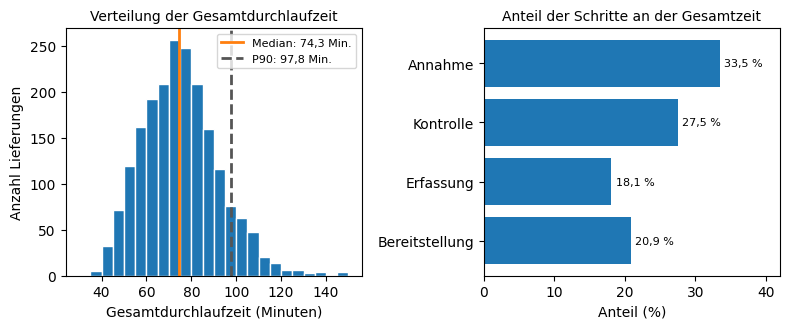

In [14]:
# Verteilung und Anteile der Schritte
BLAU, ORANGE = "#1f77b4", "#ff7f0e"

def komma(zahl):
    """Zahl als Text mit Dezimalkomma, z. B. 74,3"""
    return f"{zahl:.1f}".replace(".", ",")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.4))

# Histogramm der Gesamtdurchlaufzeit
ax1.hist(df["min_gesamt"], bins=np.arange(30, 155, 5), color=BLAU, edgecolor="white")
median, p90 = df["min_gesamt"].median(), df["min_gesamt"].quantile(0.90)
ax1.axvline(median, color=ORANGE, linestyle="-", linewidth=2, label=f"Median: {komma(median)} Min.")
ax1.axvline(p90, color="#555555", linestyle="--", linewidth=2, label=f"P90: {komma(p90)} Min.")
ax1.set_title("Verteilung der Gesamtdurchlaufzeit", fontsize=10)
ax1.set_xlabel("Gesamtdurchlaufzeit (Minuten)")
ax1.set_ylabel("Anzahl Lieferungen")
ax1.legend(fontsize=8)

# Balkendiagramm: Anteil der vier Schritte
balken = ax2.barh(schritt.index, schritt["Anteil_Prozent"], color=BLAU)
ax2.bar_label(balken, labels=[komma(a) + " %" for a in schritt["Anteil_Prozent"]], padding=3, fontsize=8)
ax2.invert_yaxis()  # erster Schritt oben
ax2.set_xlim(0, 42)
ax2.set_title("Anteil der Schritte an der Gesamtzeit", fontsize=10)
ax2.set_xlabel("Anteil (%)")

fig.tight_layout()
fig.savefig(ERG + "abb3_verteilung_schritte.png", dpi=200)
plt.show()

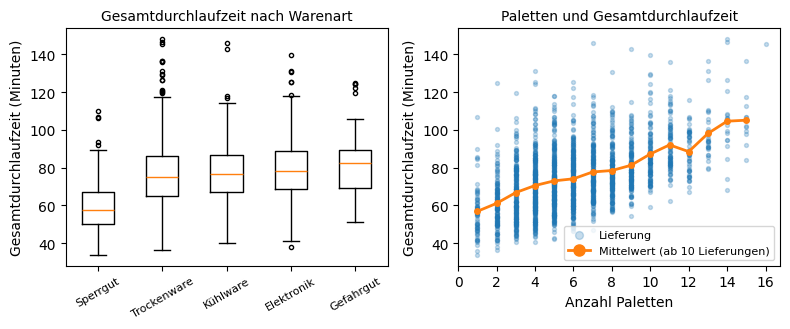

In [15]:
# Boxplot nach Warenart und Streudiagramm Paletten
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.4))

# Boxplot je Warenart, sortiert nach dem Median
reihenfolge = df.groupby("warenart")["min_gesamt"].median().sort_values().index
ax1.boxplot([df.loc[df["warenart"] == art, "min_gesamt"] for art in reihenfolge], flierprops={"markersize": 3})
ax1.set_xticks(range(1, len(reihenfolge) + 1), reihenfolge, rotation=30, fontsize=8)
ax1.set_title("Gesamtdurchlaufzeit nach Warenart", fontsize=10)
ax1.set_ylabel("Gesamtdurchlaufzeit (Minuten)")

# Streudiagramm: Paletten gegen Gesamtdurchlaufzeit
ax2.scatter(df["anzahl_paletten"], df["min_gesamt"], s=8, alpha=0.25, color=BLAU, label="Lieferung")
mittel = df.groupby("anzahl_paletten")["min_gesamt"].agg(["mean", "count"])
mittel = mittel[mittel["count"] >= 10]   # nur Palettenzahlen mit mindestens 10 Lieferungen
ax2.plot(mittel.index, mittel["mean"], color=ORANGE, marker="o", markersize=4, linewidth=2,
         label="Mittelwert (ab 10 Lieferungen)")
ax2.set_xticks(range(0, 17, 2))  # nur ganze Paletten auf der Achse
ax2.set_title("Paletten und Gesamtdurchlaufzeit", fontsize=10)
ax2.set_xlabel("Anzahl Paletten")
ax2.set_ylabel("Gesamtdurchlaufzeit (Minuten)")
ax2.legend(fontsize=8, markerscale=2, loc="lower right")

fig.tight_layout()
fig.savefig(ERG + "abb4_warenart_paletten.png", dpi=200)
plt.show()

## 6. Verbesserungsvorschläge und Wirtschaftlichkeit

In [16]:
# Einsparung je Lieferung: Wie viele Minuten würde die Maßnahme sparen? (0 = Lieferung ist nicht betroffen)
STUNDENSATZ = 19.0  # Euro pro Stunde, Fachkraft im Wareneingang
koef = modell_b.params # Koeffizienten des Endmodells

spar = pd.DataFrame(index=df.index)
spar["V1 Voranmeldung"] = (df["avisiert"] == "nein") * koef["avisiert_nein"]
spar["V2 Lieferanten LF03/LF07"] = ((df["lieferant_id"] == "LF03") * koef["lieferant_id_LF03"]
                                    + (df["lieferant_id"] == "LF07") * koef["lieferant_id_LF07"])
spar["V3 Montag entlasten"] = (df["wochentag_name"] == "Montag") * (-koef["wochentag_name_Dienstag"])

tab = pd.DataFrame({
    "Betroffen": (spar > 0).sum(),
    "Anteil_Prozent": 100 * (spar > 0).mean(),
    "Min_je_Lieferung": spar.mean(),  # Durchschnitt über ALLE Lieferungen
})
tab.loc["Summe"] = [np.nan, np.nan, tab["Min_je_Lieferung"].sum()]

tab["Umsetzung_Std"] = [6, 4, 3, 13]   # geschätzt, Reihenfolge: V1, V2, V3, Summe
tab["Umsetzung_Euro"] = tab["Umsetzung_Std"] * STUNDENSATZ
# 700 Lieferungen pro Monat = 35 Lieferungen x 20 Arbeitstage
tab["Euro_Monat_Potenzial"] = tab["Min_je_Lieferung"] * 700 / 60 * STUNDENSATZ   # 100 % des Effekts
tab["Euro_Monat_vorsichtig"] = 0.5 * tab["Euro_Monat_Potenzial"]   # 50 % des Effekts
tab["Amortisation_Monate_Potenzial"] = tab["Umsetzung_Euro"] / tab["Euro_Monat_Potenzial"]
tab["Amortisation_Monate_vorsichtig"] = tab["Umsetzung_Euro"] / tab["Euro_Monat_vorsichtig"]
print(tab.round(2).T.to_string())
tab.round(2).to_csv(ERG + "verbesserungen.csv", sep=";", encoding="utf-8-sig")

# Gesamtrechnung mit den Projektkosten (1.605 Euro aus Kapitel 2.4)
PROJEKTKOSTEN = 1605.00
gesamtkosten = PROJEKTKOSTEN + tab.loc["Summe", "Umsetzung_Euro"]
for fall in ["Potenzial", "vorsichtig"]:
    euro = tab.loc["Summe", "Euro_Monat_" + fall]
    print(f"Fall {fall}: Einsparung {euro:.2f} Euro/Monat | Amortisation (Projekt + Umsetzung): "
          f"{gesamtkosten / euro:.1f} Monate | nur Projekt: {PROJEKTKOSTEN / euro:.1f} Monate")

                                V1 Voranmeldung  V2 Lieferanten LF03/LF07  V3 Montag entlasten   Summe
Betroffen                                329.00                    459.00               454.00     NaN
Anteil_Prozent                            16.29                     22.72                22.48     NaN
Min_je_Lieferung                           1.20                      1.81                 1.01    4.02
Umsetzung_Std                              6.00                      4.00                 3.00   13.00
Umsetzung_Euro                           114.00                     76.00                57.00  247.00
Euro_Monat_Potenzial                     264.99                    402.32               223.21  890.52
Euro_Monat_vorsichtig                    132.49                    201.16               111.60  445.26
Amortisation_Monate_Potenzial              0.43                      0.19                 0.26    0.28
Amortisation_Monate_vorsichtig             0.86                      0.38

In [17]:
# In welchem Schritt entsteht der Unterschied?
def vergleich(maske, name):
    """Mittlere Schrittzeit der betroffenen Lieferungen minus Rest (Minuten)."""
    diff = df.loc[maske, schritte].mean() - df.loc[~maske, schritte].mean()
    print(name, diff.round(1).to_dict())

vergleich(df["avisiert"] == "nein", "nicht avisiert")
vergleich(df["lieferant_id"].isin(["LF03", "LF07"]), "LF03/LF07")
vergleich(df["wochentag_name"] == "Montag", "Montag")
vergleich(df["warenart"] == "Gefahrgut", "Gefahrgut")

nicht avisiert {'min_annahme': 8.8, 'min_kontrolle': 1.0, 'min_erfassung': -0.0, 'min_bereit': -0.3}
LF03/LF07 {'min_annahme': 7.1, 'min_kontrolle': 3.8, 'min_erfassung': 0.3, 'min_bereit': 0.0}
Montag {'min_annahme': 3.3, 'min_kontrolle': -0.9, 'min_erfassung': 1.5, 'min_bereit': 0.1}
Gefahrgut {'min_annahme': -3.9, 'min_kontrolle': 14.7, 'min_erfassung': -3.1, 'min_bereit': -1.9}


## 7. Tests (Qualitätssicherung)
Jeder Test ergibt `True` (bestanden) oder `False` (nicht bestanden).

In [18]:
# Test T9 vorbereiten: Modell B mit 80 % der Lieferungen lernen und mit den übrigen 20 % prüfen
lern = df.sample(frac=0.8, random_state=42).index   # Zeilennummern der Lerndaten
test = df.index.difference(lern)   # alle anderen Zeilen
modell_lern = sm.OLS(y[lern], X.loc[lern]).fit()
fehler_test = y[test] - modell_lern.predict(X.loc[test])
r2_test = 1 - (fehler_test ** 2).sum() / ((y[test] - y[test].mean()) ** 2).sum()
print("R² auf den Testdaten (20 %):", round(r2_test, 3))

tests = {
    "T1 Rohdatei unverändert (Fingerabdruck gleich)":
        hashlib.md5(open("../01_Rohdaten/wareneingang_roh.csv", "rb").read()).hexdigest() == hash_vorher,
    "T2 Zeilenbilanz: Rohzeilen = übrige + entfernte Zeilen":
        anzahl_roh == len(df) + len(pd.read_csv(ERG + "datenfehler_liste.csv", sep=";")),
    "T3 Keine fehlenden Werte und keine doppelten Lieferungen":
        df.isna().sum().sum() == 0 and not df["lieferung_id"].duplicated().any(),
    "T4 Palettenzahl 1 bis 33, genau 5 Warenarten":
        df["anzahl_paletten"].between(1, 33).all() and df["warenart"].nunique() == 5,
    "T5 Alle Schrittzeiten größer 0, Gesamtzeit 30 bis 150 Minuten":
        (df[schritte] > 0).all().all() and df["min_gesamt"].between(30, 150).all(),
    "T6 Summe der vier Schritte = Gesamtzeit":
        np.allclose(df[schritte].sum(axis=1), df["min_gesamt"]),
    "T7 Kennzahlen mit NumPy nachgerechnet (Mittelwert, Median, P90)":
        np.allclose([np.mean(df["min_gesamt"]), np.median(df["min_gesamt"]), np.percentile(df["min_gesamt"], 90)],
                    [df["min_gesamt"].mean(), df["min_gesamt"].median(), df["min_gesamt"].quantile(0.90)]),
    "T8 Regression mit NumPy nachgerechnet (Koeffizienten gleich)":
        np.allclose(np.linalg.lstsq(X.values, y.values, rcond=None)[0], modell_b.params.values),
    "T9 Modell B auch auf neuen Daten brauchbar (R² Testdaten über 0,5)":
        r2_test > 0.5,
    "T10 Keine Spalten mit Personenbezug (nur erwartete Spalten)":
        set(df.columns) == set(ZEIT + schritte + ["lieferung_id", "lieferant_id", "warenart", "anzahl_paletten",
                                                  "anzahl_positionen", "avisiert", "wochentag", "wochentag_name",
                                                  "ankunftsstunde", "min_gesamt"]),
}
for name, ok in tests.items():
    print(ok, "-", name)

R² auf den Testdaten (20 %): 0.585
True - T1 Rohdatei unverändert (Fingerabdruck gleich)
True - T2 Zeilenbilanz: Rohzeilen = übrige + entfernte Zeilen
True - T3 Keine fehlenden Werte und keine doppelten Lieferungen
True - T4 Palettenzahl 1 bis 33, genau 5 Warenarten
True - T5 Alle Schrittzeiten größer 0, Gesamtzeit 30 bis 150 Minuten
True - T6 Summe der vier Schritte = Gesamtzeit
True - T7 Kennzahlen mit NumPy nachgerechnet (Mittelwert, Median, P90)
True - T8 Regression mit NumPy nachgerechnet (Koeffizienten gleich)
True - T9 Modell B auch auf neuen Daten brauchbar (R² Testdaten über 0,5)
True - T10 Keine Spalten mit Personenbezug (nur erwartete Spalten)
